# Notebook 3: Evaluation, Churn Risk %, and SHAP Explainability

Compare all models, plot ROC curves, export churn probability scores, and run SHAP on the best model.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve,
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

ROOT = Path('..').resolve()
SPLIT_DIR = ROOT / 'ml_outputs' / 'splits'
MODEL_DIR = ROOT / 'ml_outputs' / 'models'
SHAP_DIR = ROOT / 'ml_outputs' / 'shap'
SHAP_DIR.mkdir(parents=True, exist_ok=True)

X_test = pd.read_csv(SPLIT_DIR / 'X_test.csv')
y_test = pd.read_csv(SPLIT_DIR / 'y_test.csv').squeeze()
ids_test = pd.read_csv(SPLIT_DIR / 'ids_test.csv').squeeze()
comparison = pd.read_csv(ROOT / 'ml_outputs' / 'model_comparison.csv')
model_names = comparison['model'].tolist()
print(comparison.to_string(index=False))

              model  accuracy  precision  recall     f1  roc_auc
           catboost    0.7580     0.5288  0.8102 0.6399   0.8571
                mlp    0.8048     0.6542  0.5615 0.6043   0.8558
           lightgbm    0.7615     0.5336  0.8075 0.6426   0.8558
logistic_regression    0.7523     0.5216  0.8075 0.6338   0.8552
      random_forest    0.7736     0.5551  0.7406 0.6346   0.8543
            xgboost    0.7587     0.5308  0.7834 0.6328   0.8541
  gradient_boosting    0.8077     0.6722  0.5374 0.5973   0.8539
            svm_rbf    0.7402     0.5068  0.7995 0.6203   0.8515
           adaboost    0.7984     0.6406  0.5481 0.5908   0.8510
                knn    0.7757     0.5863  0.5267 0.5549   0.8332


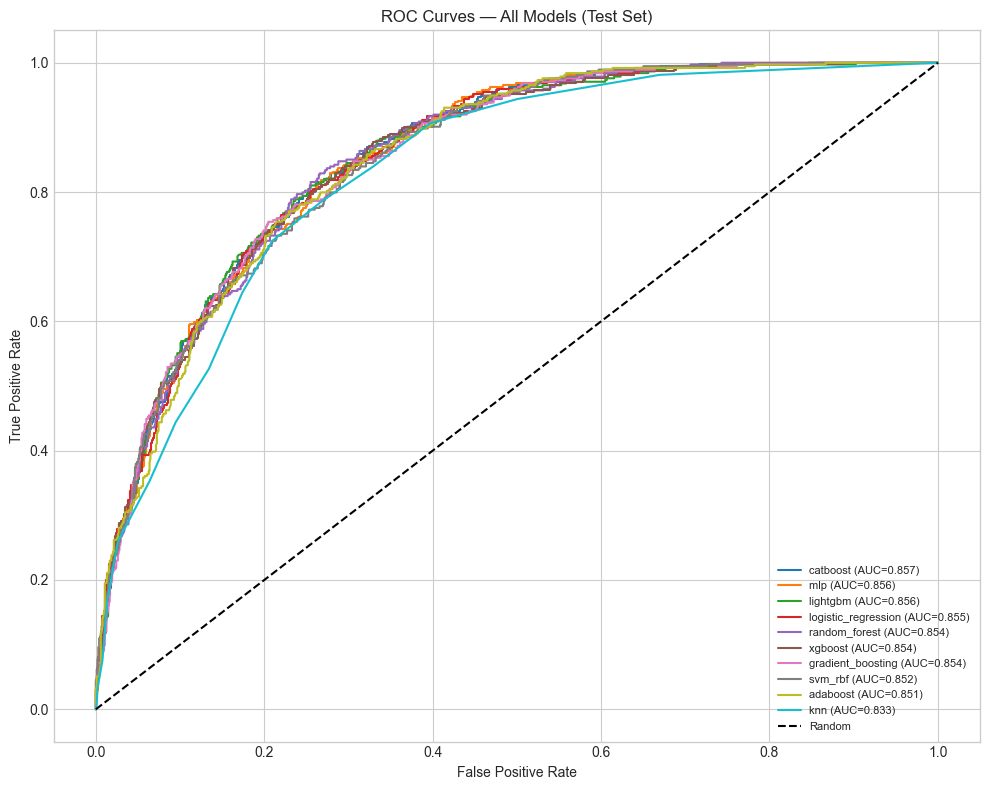

In [2]:
fig, ax = plt.subplots(figsize=(10, 8))
for name in model_names:
    pipe = joblib.load(MODEL_DIR / f'{name}_best.joblib')
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Models (Test Set)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(ROOT / 'ml_outputs' / 'roc_curves.png', dpi=150)
plt.show()

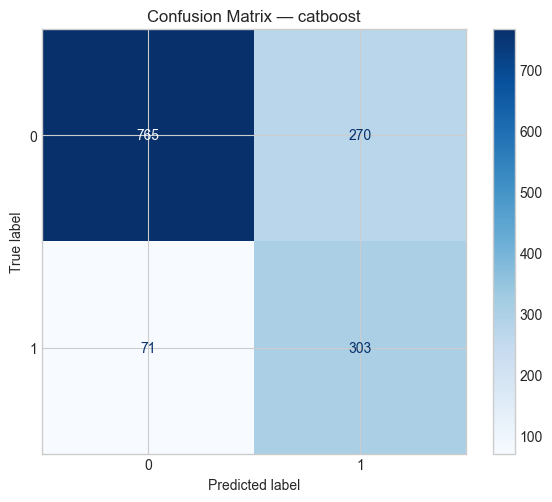

Best model: catboost
ROC-AUC: 0.8571
Accuracy: 0.7580
F1: 0.6399


In [3]:
best_name = comparison.iloc[0]['model']
best_model = joblib.load(MODEL_DIR / 'best_model.joblib')
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues')
ax.set_title(f'Confusion Matrix — {best_name}')
plt.tight_layout()
plt.savefig(ROOT / 'ml_outputs' / 'confusion_matrix_best.png', dpi=150)
plt.show()

print(f'Best model: {best_name}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}')
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'F1: {f1_score(y_test, y_pred):.4f}')

In [4]:
predictions = pd.DataFrame({
    'CustomerID': ids_test,
    'actual_churn': y_test.values,
    'churn_risk_pct': np.round(y_prob * 100, 2),
    'predicted_churn': y_pred,
})

for name in model_names:
    pipe = joblib.load(MODEL_DIR / f'{name}_best.joblib')
    predictions[f'{name}_risk_pct'] = np.round(pipe.predict_proba(X_test)[:, 1] * 100, 2)

predictions.to_csv(ROOT / 'ml_outputs' / 'churn_predictions.csv', index=False)
predictions.head(10)

,CustomerID,actual_churn,churn_risk_pct,predicted_churn,catboost_risk_pct,mlp_risk_pct,lightgbm_risk_pct,logistic_regression_risk_pct,random_forest_risk_pct,xgboost_risk_pct,gradient_boosting_risk_pct,svm_rbf_risk_pct,adaboost_risk_pct,knn_risk_pct
0,4376-KFVRS,0,14.37,0,14.37,11.00,29.26,19.30,12.31,24.030001,7.22,5.99,34.85,20.00
1,2754-SDJRD,0,91.54,1,91.54,76.09,88.60,85.34,80.93,90.050003,84.20,59.65,52.76,66.67
2,9917-KWRBE,0,32.06,0,32.06,10.61,28.97,23.36,19.82,38.020000,9.76,5.83,39.61,0.00
3,0365-GXEZS,0,65.52,1,65.52,42.00,67.67,73.99,60.08,63.450001,43.49,49.10,51.08,60.00
4,9385-NXKDA,0,6.33,0,6.33,3.79,5.39,12.62,5.50,4.370000,3.81,3.44,31.86,0.00
5,4686-UXDML,0,78.83,1,78.83,71.53,73.95,82.72,70.13,76.809998,57.58,62.54,51.96,53.33
6,2227-JRSJX,0,68.18,1,68.18,46.18,67.36,69.87,63.45,71.470001,47.46,51.46,48.48,53.33
7,4830-FAXFM,0,20.70,0,20.70,7.29,20.17,18.77,14.40,13.110000,6.72,5.55,39.23,6.67
8,1830-IPXVJ,0,0.15,0,0.15,0.26,0.54,0.34,0.01,0.480000,0.95,1.13,21.89,0.00
9,4690-LLKUA,1,62.28,1,62.28,35.20,58.98,56.32,59.82,61.279999,36.18,48.78,47.37,46.67


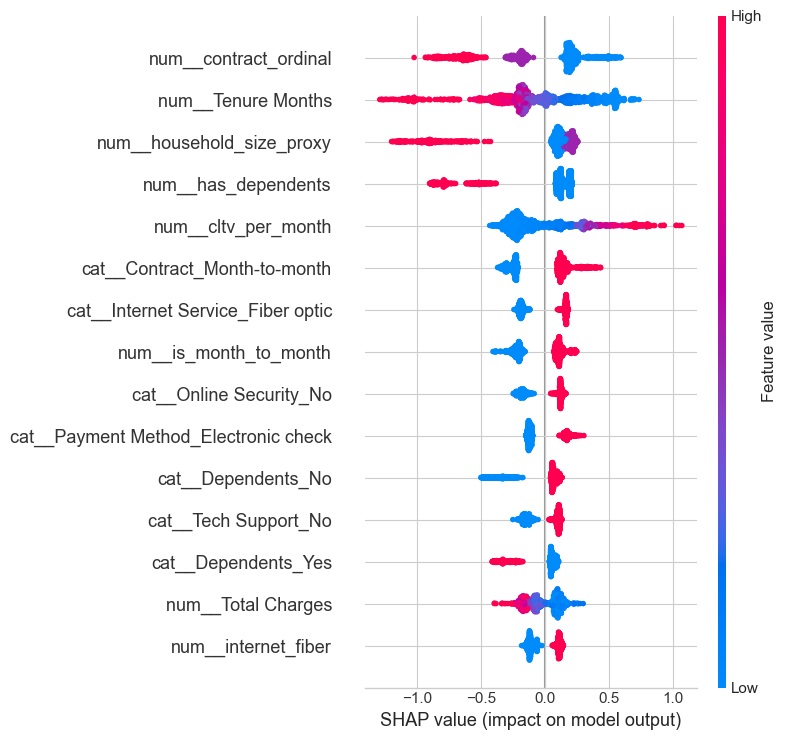

In [5]:
tree_models = {'random_forest', 'gradient_boosting', 'adaboost', 'xgboost', 'lightgbm', 'catboost'}
X_test_transformed = best_model.named_steps['prep'].transform(X_test)

if hasattr(best_model.named_steps['prep'], 'get_feature_names_out'):
    feature_names = best_model.named_steps['prep'].get_feature_names_out()
else:
    feature_names = [f'f{i}' for i in range(X_test_transformed.shape[1])]

model_est = best_model.named_steps['model']

if best_name in tree_models:
    explainer = shap.TreeExplainer(model_est)
    shap_values = explainer.shap_values(X_test_transformed)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
elif best_name == 'logistic_regression':
    explainer = shap.LinearExplainer(model_est, X_test_transformed)
    shap_values = explainer.shap_values(X_test_transformed)
else:
    background = shap.sample(X_test_transformed, 100, random_state=42)
    explainer = shap.KernelExplainer(model_est.predict_proba, background)
    shap_values = explainer.shap_values(X_test_transformed[:200], nsamples=100)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    X_test_transformed = X_test_transformed[:200]

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=15)
plt.tight_layout()
plt.savefig(SHAP_DIR / 'shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

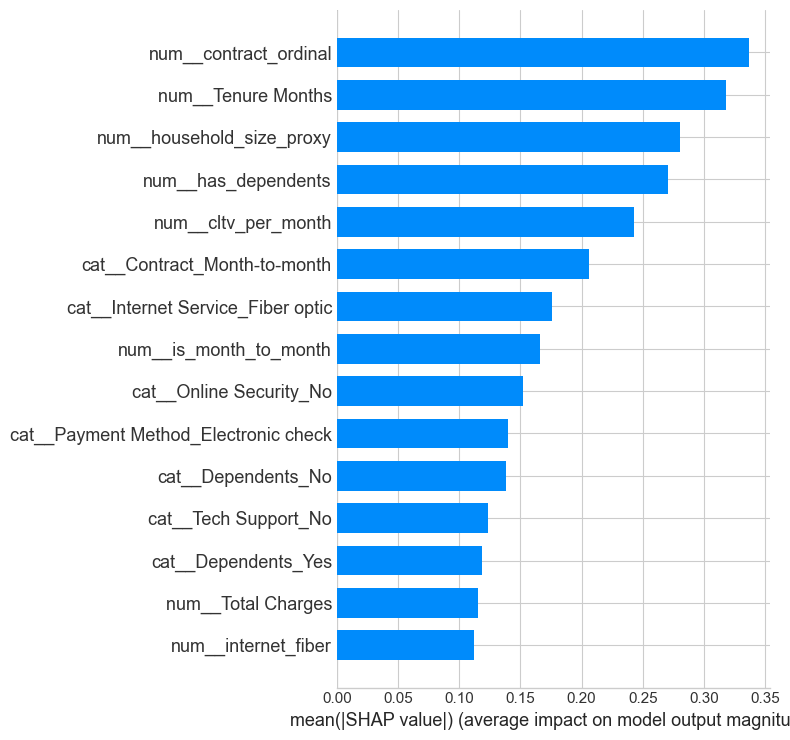

,feature,mean_abs_shap
0,num__contract_ordinal,0.3372
1,num__Tenure Months,0.3176
2,num__household_size_proxy,0.2804
3,num__has_dependents,0.2708
4,num__cltv_per_month,0.2427
5,cat__Contract_Month-to-month,0.2061
6,cat__Internet Service_Fiber optic,0.1754
7,num__is_month_to_month,0.1657
8,cat__Online Security_No,0.1519
9,cat__Payment Method_Electronic check,0.1399


In [6]:
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, plot_type='bar', show=False, max_display=15)
plt.tight_layout()
plt.savefig(SHAP_DIR / 'shap_importance_bar.png', dpi=150, bbox_inches='tight')
plt.show()

mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_idx = np.argsort(mean_abs_shap)[::-1][:15]
shap_top = pd.DataFrame({
    'feature': [feature_names[i] for i in top_idx],
    'mean_abs_shap': mean_abs_shap[top_idx],
}).round(4)
shap_top.to_csv(SHAP_DIR / 'shap_top_features.csv', index=False)
shap_top

In [7]:
if hasattr(model_est, 'feature_importances_'):
    imp = pd.DataFrame({
        'feature': feature_names,
        'importance': model_est.feature_importances_,
    }).sort_values('importance', ascending=False).head(15)
    imp.to_csv(SHAP_DIR / 'feature_importance_best_model.csv', index=False)
    print('Top feature importances:')
    print(imp.to_string(index=False))

summary = {
    'best_model': best_name,
    'test_metrics': comparison[comparison['model'] == best_name].iloc[0].to_dict(),
    'top_shap_features': shap_top.head(10).to_dict(orient='records'),
}
with open(ROOT / 'ml_outputs' / 'phase3_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print('\nPhase 3 evaluation complete. Outputs in ml_outputs/')

Top feature importances:
                          feature  importance
            num__contract_ordinal   11.010773
              num__has_dependents   10.767285
        num__household_size_proxy    8.733789
               num__Tenure Months    7.025274
     cat__Contract_Month-to-month    7.024839
              num__cltv_per_month    5.582360
              cat__Dependents_Yes    5.091977
               cat__Dependents_No    3.958124
           num__is_month_to_month    3.924657
                        num__CLTV    3.285573
           num__avg_monthly_spend    2.922655
               num__Total Charges    2.300878
                num__charge_drift    2.088660
cat__Internet Service_Fiber optic    1.990876
          cat__Online Security_No    1.990604

Phase 3 evaluation complete. Outputs in ml_outputs/
